In [1]:
# Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import math
import ipynbname
import os
import networkx as nx

In [2]:
## Functions

def df_logistic(x, r=4.0):
    """Derivative of the logistic map: f'(x) = r * (1 - 2x)"""
    return r * (1.0 - 2.0 * x)

def df_circle(x, r=0.35, K=6.9115):
    """Derivative of the circle map: f'(x) = 1 - K * cos(2 * pi * x)"""
    return 1.0 - K * np.cos(2.0 * np.pi * x)
    
def logistic(x0, r=4):
    x0 = np.asarray(x0)
    y = r*x0*(1-x0)
    return y
    
def circle(x0, r=0.35, K=6.9115):
    x0 = np.asarray(x0)
    y= x0+r-(K/(2*math.pi))*np.sin(2*math.pi*x0)
    y = y%1
    return y

def simulate_discrete_models(x0, f, df, A, t, alpha=0.1, n_transient=1000, **params):
    """
    Simulates coupled map trajectories and calculates the full Lyapunov spectrum.

    Parameters:
    -----------
    x0          : 1D array of initial node states (shape: (M,))
    f           : Local map function f(x, **params)
    df          : Derivative of local map df(x, **params)
    A           : Adjacency matrix (shape: (M, M))
    t           : Total recording steps (after transients)
    alpha       : Coupling strength in [0, 1]
    n_transient : Warm-up iterations to let trajectory reach the attractor
    **params    : Extra parameters passed to f and df

    Returns:
    --------
    traj        : 2D array (t, M) of node states
    lyap_exp    : 1D array (M,) of Lyapunov exponents sorted in descending order
    """
    x = np.asarray(x0, dtype=float).copy()
    A = np.asarray(A, dtype=float)
    M = A.shape[0]

    # Precompute row-normalized transition matrix W
    degree = np.sum(A, axis=1)
    degree_safe = np.where(degree == 0, 1.0, degree)
    W = A / degree_safe[:, np.newaxis]

    # Preserve state for isolated nodes
    isolated_mask = (degree == 0)
    if np.any(isolated_mask):
        W[isolated_mask, :] = 0.0
        W[isolated_mask, isolated_mask] = 1.0

    # Effective linear coupling operator: M_net = (1 - alpha) * I + alpha * W
    M_net = (1.0 - alpha) * np.eye(M) + alpha * W

    # 1. Transient burn-in (lets state settle onto the attractor)
    for _ in range(n_transient):
        f_x = f(x, **params)
        x = M_net @ f_x

    # 2. Main loop: recording trajectories and tracking perturbations
    traj = np.zeros((t, M), dtype=float)
    traj[0] = x

    # Initialize orthonormal tangent frame Q and running sum of log expansion rates
    Q = np.eye(M, dtype=float)
    lyap_sum = np.zeros(M, dtype=float)

    for step in range(1, t):
        # Local state and local derivatives
        f_x = f(x, **params)
        f_prime = df(x, **params)  # shape: (M,)

        # Next state
        x = M_net @ f_x
        traj[step] = x

        # Jacobian J = M_net @ diag(f')
        # Efficient column-scaling: M_net * f_prime avoids an explicit diag() allocation
        J = M_net * f_prime

        # Propagate tangent vectors: Z = J @ Q
        Z = J @ Q

        # Re-orthonormalize via QR decomposition
        Q, R = np.linalg.qr(Z)

        # Accumulate log expansion factors (diagonal elements of upper-triangular R)
        # abs avoids negative values from possible reflection components
        lyap_sum += np.log(np.abs(np.diag(R)))

    # Compute average rates of divergence
    lyap_exp = lyap_sum / (t - 1)
    lyap_exp = np.sort(lyap_exp)[::-1]  # Sort descending (lambda_1 >= lambda_2 >= ...)

    return traj, lyap_exp

## Simulation of Coupled Logistic & Circle Maps 

Here, we re-generate the results in Table 3.2 in the PhD Thesis to validate the result. 

In [3]:
network_16nodes = np.loadtxt("../../Files/16nodes.txt")
Adj = network_16nodes
M = Adj.shape[0]
rng = np.random.default_rng()
x0 = rng.random((M,))
t= 10**5
n_transient = 10**4
alpha = 0.1

Traj_log, Lya_spec_log = simulate_and_lyapunov(x0, 
                      f=logistic, df=df_logistic, 
                      A=Adj, t=t,
                      alpha=alpha, 
                      n_transient=n_transient, 
                      r=4.0)

In [4]:
np.round(Lya_spec_log,2)

array([0.45, 0.44, 0.44, 0.43, 0.42, 0.42, 0.41, 0.4 , 0.39, 0.38, 0.37,
       0.36, 0.34, 0.32, 0.29, 0.25])

In [5]:
Traj_circ, Lya_spec_circ = simulate_and_lyapunov(x0, 
                      f=circle, df=df_circle,
                      A=Adj, t=t,
                      alpha=alpha, 
                      n_transient=n_transient, 
                      r=0.35,K=6.9115)
np.round(Lya_spec_circ, 2)

array([1.21, 1.18, 1.15, 1.12, 1.09, 1.07, 1.04, 1.  , 0.96, 0.92, 0.88,
       0.83, 0.77, 0.7 , 0.61, 0.47])

<div style='text-align:center'> <h2> Bifurcation Diagram and Maximum Lyapunov Exponent</h2> </div>

We re-produce the Figure 3.9 (Bifurcation diagram and MLE) on the page 44 of the PhD Thesis. 

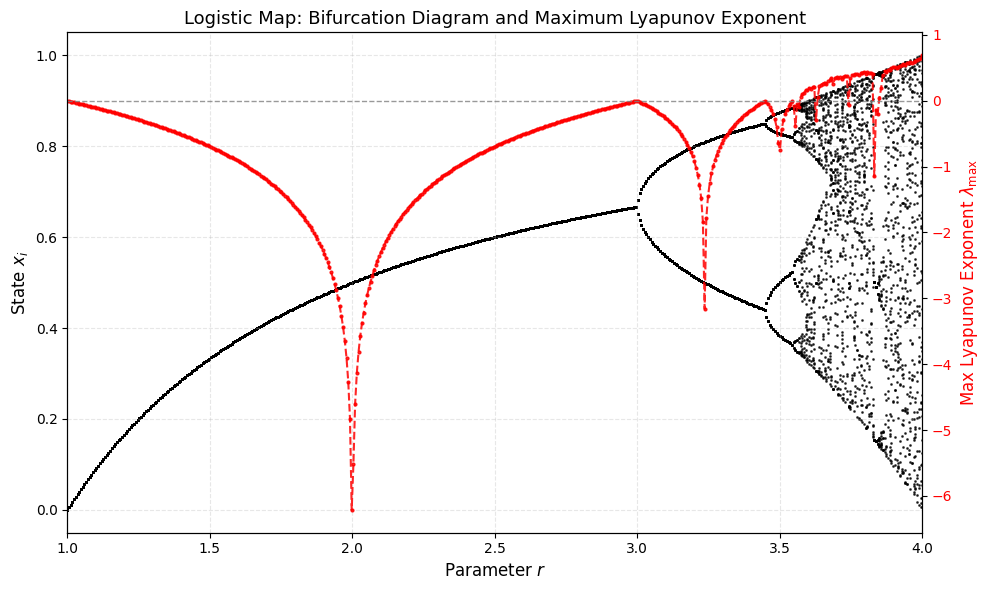

In [6]:
notebook_name = ipynbname.name()
# Create the directory if it does not already exist
output_dir = f"Output_{notebook_name}"
os.makedirs(output_dir, exist_ok=True)

## # # # # # # # # # # # # ## ## ## ## ## ## ## ## 
Adj = np.array([[1]])
M = Adj.shape[0]
rng = np.random.default_rng()
x0 = rng.random((M,))
t= 10**4
n_transient = 10**3
alpha = 0
r_range = np.linspace(1, 4, num=500)


# Number of tail points to extract per node to capture the steady-state attractor
tail_points = 10*3

# Containers to store results across the entire parameter sweep
all_r_bif = []
all_x_bif = []
r_vals = []
max_lya = []

for i, r in enumerate(r_range):
    Traj_log, Lya_spec_log = simulate_and_lyapunov(x0, 
                      f=logistic, df=df_logistic, 
                      A=Adj, t=t,
                      alpha=alpha, 
                      n_transient=n_transient, 
                      r=r)
    # 1. Steady-state trajectory states (black points)
    steady_states = Traj_log[-tail_points:].flatten() 
    all_x_bif.extend(steady_states)
    all_r_bif.extend([r] * len(steady_states))

    # 2. Maximum Lyapunov Exponent (red points)
    r_vals.append(r)
    max_lya.append(np.max(Lya_spec_log))

        # # # ## # # # # # # # # 
        # # # # # --- Plotting --- # # #
        # # # # # # # # # # # # # 
    
fig, ax1 = plt.subplots(figsize=(10, 6))

# Left Axis: Bifurcation Diagram (black points)
ax1.scatter(
    all_r_bif,
    all_x_bif,
    color="black",
    s=1,
    alpha=0.7,
    rasterized=True,
    label="Attractor states $(r, x)$",
)
ax1.set_xlabel("Parameter $r$", fontsize=12)
ax1.set_ylabel("State $x_i$", color="black", fontsize=12)
ax1.set_xlim(r_range[0], r_range[-1])
ax1.set_ylim(-0.05, 1.05)
ax1.tick_params(axis="y", labelcolor="black")
ax1.grid(True, linestyle="--", alpha=0.3)

# Right Axis: Maximum Lyapunov Exponent (red points)
ax2 = ax1.twinx()
ax2.plot(
    r_vals,
    max_lya,
    "o--",
    color="red",
    markersize=2,
    alpha=0.85,
    label=r"$\max(\lambda)$",
)
ax2.axhline(0, color="gray", linestyle="--", linewidth=1.0, alpha=0.8)
ax2.set_ylabel(
    r"Max Lyapunov Exponent $\lambda_{\max}$", color="red", fontsize=12
)
ax2.tick_params(axis="y", labelcolor="red")

# Title and Layout
plt.title(
    "Logistic Map: Bifurcation Diagram and Maximum Lyapunov Exponent",
    fontsize=13,
)
fig.tight_layout()
plt.savefig(f"{output_dir}/logistic_bifurcation_mle.tiff", dpi=300, bbox_inches="tight")    
plt.show()


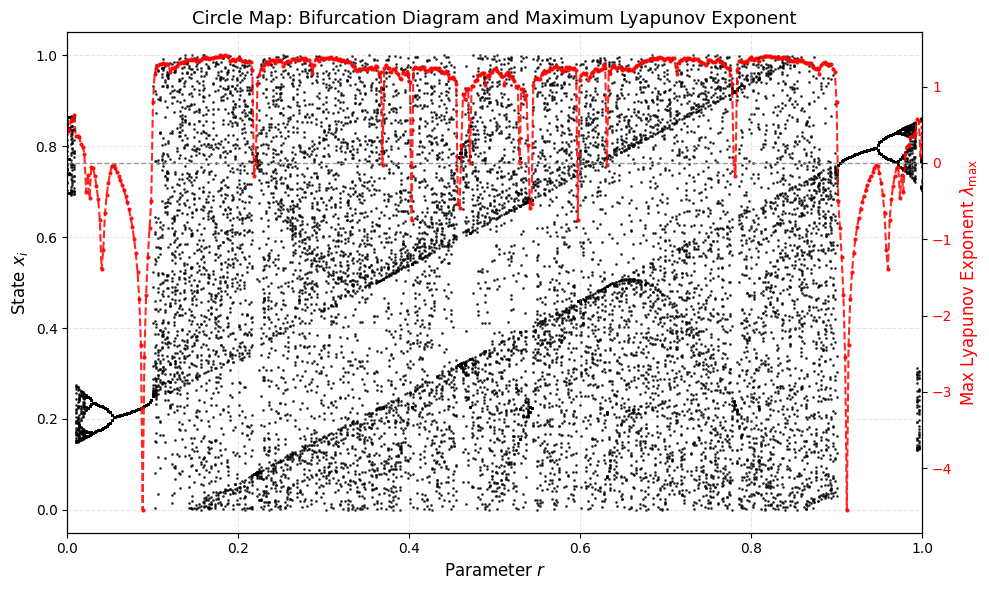

In [7]:

r_range = np.linspace(0, 1, num=500)

# Containers to store results across the entire parameter sweep
all_r_bif = []
all_x_bif = []
r_vals = []
max_lya = []

for i, r in enumerate(r_range):
    Traj_circ, Lya_spec_circ = simulate_and_lyapunov(x0, 
                      f=circle, df=df_circle, 
                      A=Adj, t=t,
                      alpha=alpha, 
                      n_transient=n_transient, 
                      r=r,K=6.9115)
    # 1. Steady-state trajectory states (black points)
    steady_states = Traj_circ[-tail_points:].flatten() 
    all_x_bif.extend(steady_states)
    all_r_bif.extend([r] * len(steady_states))

    # 2. Maximum Lyapunov Exponent (red points)
    r_vals.append(r)
    max_lya.append(np.max(Lya_spec_circ))

    # # # ## # # # # # # # # 
# # # # # --- Plotting --- # # #
# # # # # # # # # # # # # 
fig, ax1 = plt.subplots(figsize=(10, 6))

# Left Axis: Bifurcation Diagram (black points)
ax1.scatter(
    all_r_bif,
    all_x_bif,
    color="black",
    s=1,
    alpha=0.7,
    rasterized=True,
    label="Attractor states $(r, x)$",
)
ax1.set_xlabel("Parameter $r$", fontsize=12)
ax1.set_ylabel("State $x_i$", color="black", fontsize=12)
ax1.set_xlim(r_range[0], r_range[-1])
ax1.set_ylim(-0.05, 1.05)
ax1.tick_params(axis="y", labelcolor="black")
ax1.grid(True, linestyle="--", alpha=0.3)

# Right Axis: Maximum Lyapunov Exponent (red points)
ax2 = ax1.twinx()
ax2.plot(
    r_vals,
    max_lya,
    "o--",
    color="red",
    markersize=2,
    alpha=0.85,
    label=r"$\max(\lambda)$",
)
ax2.axhline(0, color="gray", linestyle="--", linewidth=1.0, alpha=0.8)
ax2.set_ylabel(
    r"Max Lyapunov Exponent $\lambda_{\max}$", color="red", fontsize=12
)
ax2.tick_params(axis="y", labelcolor="red")

# Title and Layout
plt.title(
    "Circle Map: Bifurcation Diagram and Maximum Lyapunov Exponent",
    fontsize=13,
)
fig.tight_layout()
plt.savefig(f"{output_dir}/circle_bifurcation_mle.tiff", dpi=300, bbox_inches="tight")    
plt.show()
